# 02 · Configuración y datos

Este proyecto predice la **solubilidad acuosa** (logS) de moléculas orgánicas
a partir de descriptores 2D calculados con RDKit, usando cuatro familias de
modelos de aprendizaje automático.

**Datasets:**

- **AqSolDB** (Sorkun, Khetan & Er, 2019, *Scientific Data*): 9,982 compuestos
  con solubilidad medida, curados a partir de 9 fuentes públicas distintas.
  Se usa como conjunto de entrenamiento.
- **Delaney / ESOL** (Delaney, 2004, *J. Chem. Inf. Comput. Sci.*): 1,128
  compuestos con solubilidad medida. Se usa como **validación externa**.
- **Second Solubility Challenge** (Conn, J.G.M., Carter, J.W., Brémond, E., et al. (2023)):
    100 moleculas en Tight y 32 moleculas en Loose

Como AqSolDB incorpora, entre sus 9 fuentes, al propio conjunto de Delaney
y numerosas moleculas de los conjuntos del Second Solubility Challenge
(ver notebook 01), aquí ya se trabaja con las versiones **depuradas de
solapamiento**: ninguna molécula de estos conjuntos está presente en el 
set de entrenamiento.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import joblib
from datetime import datetime

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 1  # semilla unica para todo el proyecto
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

# Paleta de colores
COLORES = {
    'Ridge': '#1f77b4',
    'Random Forest': '#ff7f0e',
    'XGBoost': '#2ca02c',
    'LightGBM': '#d62728',
    'Interpretable': '#9467bd',
    'Potencia bruta': '#8c564b',
}

print("Configuración global cargada")
print(f"Semilla: {RANDOM_STATE}")

Configuración global cargada
Semilla: 1


In [2]:
df_entrenamiento = pd.read_csv('../data/processed/df_aqsoldb_entrenamiento.csv')
df_validacion_interna = pd.read_csv('../data/processed/df_aqsoldb_validacion_externa.csv')
df_validacion_externa1 = pd.read_csv('../data/processed/df_delaney_complete.csv')
df_validacion_externa2 = pd.read_csv('../data/processed/df_tight_complete.csv')
df_validacion_externa3 = pd.read_csv('../data/processed/df_loose_complete.csv')

print("="*60)
print("RESUMEN DE LOS CONJUNTOS DE DATOS")
print("="*60)
for nombre, df, col in [
    ('Entrenamiento (AqSolDB, depurado)', df_entrenamiento, 'Solubility'),
    ('Validación interna (AqSolDB, SD=0)', df_validacion_interna, 'Solubility'),
    ('Validación externa1 (Delaney/ESOL)', df_validacion_externa1, 'measured log solubility in mols per litre'),
    ('Validación externa2 (Tight_SC-2)', df_validacion_externa2, 'Solubility'),
    ('Validación externa3 (Loose_SC-2)', df_validacion_externa3, 'Solubility')
]:
    print(f"\n{nombre}")
    print(f"  Moléculas: {len(df):,}")
    print(f"  logS: [{df[col].min():.2f}, {df[col].max():.2f}]  media={df[col].mean():.3f}  sd={df[col].std():.3f}")

RESUMEN DE LOS CONJUNTOS DE DATOS

Entrenamiento (AqSolDB, depurado)
  Moléculas: 6,592
  logS: [-12.06, 1.97]  media=-2.929  sd=2.359

Validación interna (AqSolDB, SD=0)
  Moléculas: 1,316
  logS: [-13.17, 2.14]  media=-2.975  sd=2.411

Validación externa1 (Delaney/ESOL)
  Moléculas: 1,128
  logS: [-11.60, 1.58]  media=-3.050  sd=2.096

Validación externa2 (Tight_SC-2)
  Moléculas: 100
  logS: [-6.79, -1.18]  media=-4.027  sd=1.272

Validación externa3 (Loose_SC-2)
  Moléculas: 32
  logS: [-10.40, -1.24]  media=-5.241  sd=2.176


##### Vista general de los tres conjuntos

Antes de entrenar nada, conviene ver si los cinco conjuntos cubren rangos de
solubilidad comparables. Si la validación externa cubriera un rango muy
distinto al de entrenamiento, cualquier comparación posterior sería injusta
para el modelo.

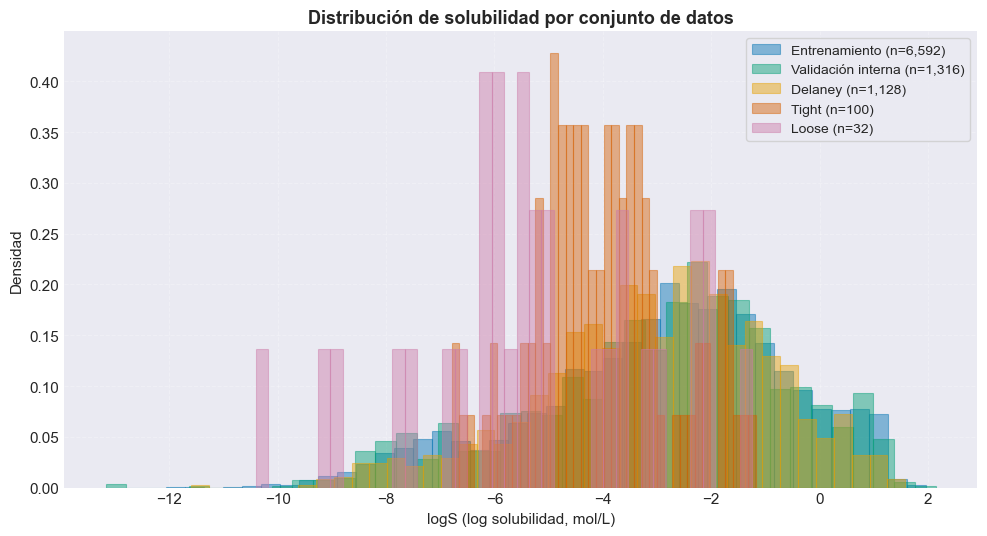

In [3]:
# Paleta Okabe-Ito: accesible a daltonismo.
PALETA = {
    'Entrenamiento':       '#0072B2',
    'Validación interna':  '#009E73',
    'Delaney':             '#E69F00',
    'Tight':               '#D55E00',
    'Loose':               '#CC79A7',
}

conjuntos_para_graficar = [
    ('Entrenamiento',      df_entrenamiento['Solubility']),
    ('Validación interna', df_validacion_interna['Solubility']),
    ('Delaney',            df_validacion_externa1['measured log solubility in mols per litre']),
    ('Tight',              df_validacion_externa2['Solubility']),
    ('Loose',              df_validacion_externa3['Solubility']),
]

fig, ax = plt.subplots(figsize=(10, 5.5))

for nombre, valores in conjuntos_para_graficar:
    ax.hist(
        valores, bins=40, alpha=0.45, density=True,
        label=f"{nombre} (n={len(valores):,})",
        color=PALETA[nombre],
        edgecolor=PALETA[nombre], linewidth=0.8,
    )

ax.set_xlabel('logS (log solubilidad, mol/L)', fontsize=11)
ax.set_ylabel('Densidad', fontsize=11)
ax.set_title('Distribución de solubilidad por conjunto de datos', fontsize=13, fontweight='bold')
ax.legend(frameon=True, fontsize=10, loc='best')
ax.grid(alpha=0.25, linestyle='--')
ax.set_axisbelow(True)

plt.tight_layout()
os.makedirs('../resultados/graficos', exist_ok=True)
plt.savefig('../resultados/graficos/00_distribucion_solubilidad.png', dpi=150, bbox_inches='tight')
plt.show()

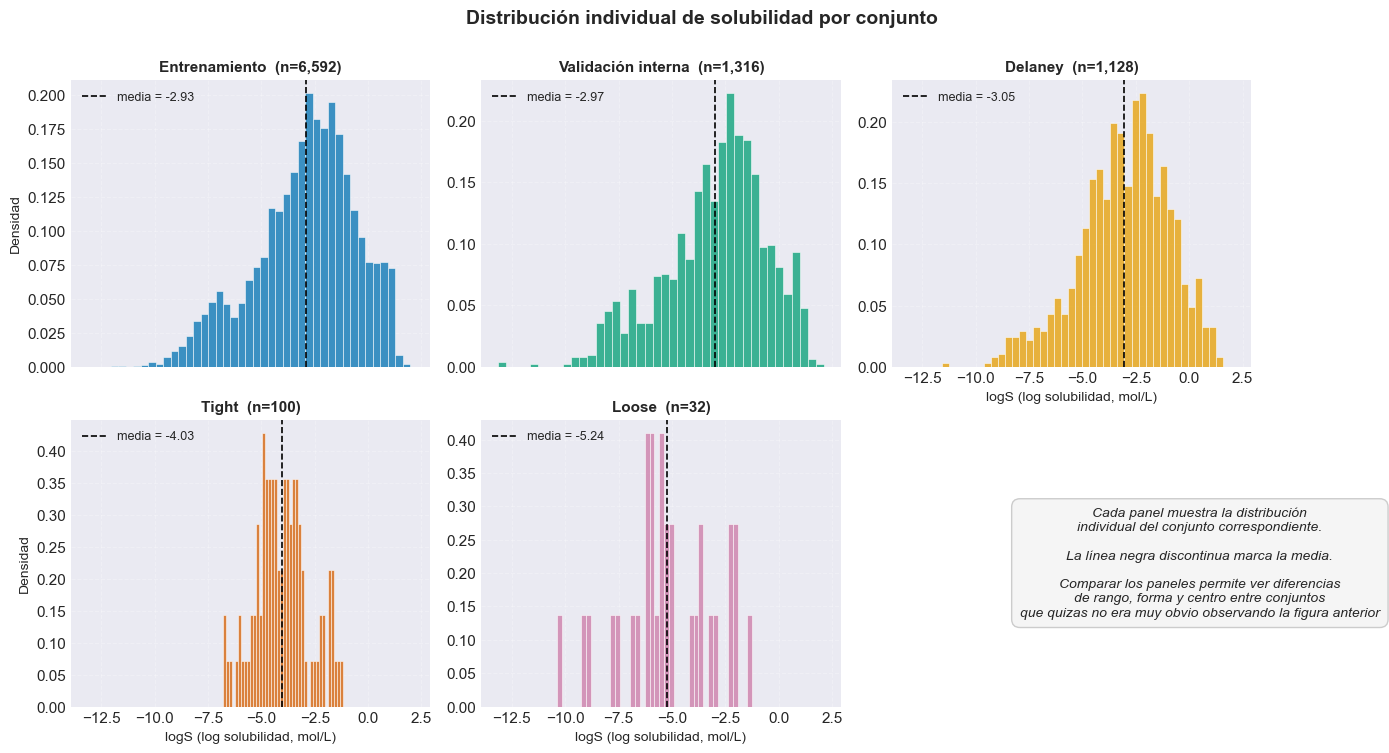

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
axes = axes.flatten()

for i, (nombre, valores) in enumerate(conjuntos_para_graficar):
    ax = axes[i]
    ax.hist(
        valores, bins=40, density=True,
        color=PALETA[nombre], alpha=0.75,
        edgecolor='white', linewidth=0.5,
    )
    ax.set_title(f"{nombre}  (n={len(valores):,})", fontsize=11, fontweight='bold')
    ax.grid(alpha=0.25, linestyle='--')
    ax.set_axisbelow(True)
    # Línea vertical con la media
    media = valores.mean()
    ax.axvline(media, color='black', linestyle='--', linewidth=1.2,
               label=f'media = {media:.2f}')
    ax.legend(fontsize=9, loc='upper left')

# Recuadro en el subplot vacio
axes[-1].axis('off')
axes[-1].text(
    0.5, 0.5,
    "Cada panel muestra la distribución\nindividual del conjunto correspondiente.\n\n"
    "La línea negra discontinua marca la media.\n\n"
    "Comparar los paneles permite ver diferencias\n"
    "de rango, forma y centro entre conjuntos\n"
    "que quizas no era muy obvio observando la figura anterior",
    ha='center', va='center', fontsize=10, style='italic',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='#F5F5F5', edgecolor='#CCCCCC'),
)

axes[2].tick_params(axis='x', which='both', labelbottom=True)

# Etiquetas del eje X  en los paneles de la fila inferior
for ax in axes[2:5]:
    ax.set_xlabel('logS (log solubilidad, mol/L)', fontsize=10)

# Etiqueta del eje Y
for ax in [axes[0], axes[3]]:
    ax.set_ylabel('Densidad', fontsize=10)

fig.suptitle('Distribución individual de solubilidad por conjunto', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../resultados/graficos/00_distribucion_solubilidad_grid.png', dpi=150, bbox_inches='tight')
plt.show()